## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import re
import sys
import time
import random
import numpy as np
import pandas as pd
import lightgbm as lgb
import sklearn
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from collections import Counter
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             explained_variance_score, accuracy_score, f1_score,
                             balanced_accuracy_score, cohen_kappa_score,
                             roc_auc_score, confusion_matrix)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.decomposition import PCA

random.seed(42)
np.random.seed(42)

SEED        = 42
TOP_K       = 200      # markers retained per selection pass
N_SPLITS    = 5        # outer CV folds
N_BOOT      = 50       # resamples for stability selection
BOOT_FRAC   = 0.80     # sample fraction per resample
STAB_THRESH = 0.60     # marker must survive this share of resamples
N_STRUCT_PC = 10       # genotype PCs used as structure covariates
CLUMP_KB    = 250      # window for collapsing markers into one locus
N_EST       = 1500     # boosting rounds before early stopping
IMP_TYPE    = 'gain'   # importance = total split gain
ALPHAS      = np.logspace(0, 4, 9)   # Ridge alpha grid, searched inside each training fold

OUT = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'

kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

print("python    ", sys.version.split()[0])
print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("scipy     ", scipy.__version__)
print("sklearn   ", sklearn.__version__)
print("lightgbm  ", lgb.__version__)
print("output dir", OUT)

python     3.12.13
numpy      2.0.2
pandas     2.3.3
scipy      1.16.3
sklearn    1.6.1
lightgbm   4.6.0
output dir /kaggle/working


## 2. Data Loading

Two files are merged on accession ID: the SNP matrix with phenotypes, and cultivar metadata
carrying subpopulation labels. Genotypes use additive 0/1/2 encoding, the count of alternate alleles.
Paths below are for Kaggle; change them if running elsewhere.

In [5]:
df = pd.read_csv("/kaggle/input/datasets/roma06yadav/filt-ricevarmap/reduced_df_529x5010.csv")
dfm = pd.read_csv("/kaggle/input/datasets/meghana4612avp/matched-data/matched_data.csv")
dfm.rename(columns={'Cultivar ID': 'id_name'}, inplace=True)

def_mer = pd.merge(df, dfm, on='id_name', how='left')

traits = ['Plant_height', 'Heading_date', 'Num_panicles',
          'Num_effective_panicles', 'Yield', 'Grain_weight',
          'Spikelet_length', 'Grain_length', 'Grain_width', 'Grain_thickness']

snp_cols = [c for c in def_mer.columns if c.startswith('vg')]
def_mer = def_mer[snp_cols + traits + ['Subpopulation']]

le = LabelEncoder()
def_mer['subpop_encoded'] = le.fit_transform(def_mer['Subpopulation'].fillna('Unknown'))
def_mer.drop(columns=['Subpopulation'], inplace=True)

print("merged shape:", def_mer.shape)
print("markers:", len(snp_cols), " traits:", len(traits))
print("subpopulations:", list(le.classes_))

merged shape: (529, 5011)
markers: 5000  traits: 10
subpopulations: ['Aus', 'Indica I', 'Indica II', 'Indica III', 'Indica Intermediate', 'Intermediate', 'Japonica Intermediate', 'Temperate Japonica', 'Tropical Japonica', 'VI/Aromatic']


### 2.1 The `-9` sentinel

RiceVarMap encodes missing phenotypes as `-9`, following PLINK convention. Code that tests only for
`NaN` does not catch this, and affected rows enter the model as genuine measurements. An accession
with a recorded grain length of -9 mm is an extreme outlier in a variable whose true range is about
6 to 11 mm.

Between one and eight rows per trait are affected. The consequence is far larger than that count
suggests: grain thickness R2 went from -0.086 to roughly 0.46 once the rows were removed.

In [6]:
for t in traits:
    def_mer[t] = def_mer[t].replace(-9, np.nan)

print(f"{'Trait':<25} {'n':>5} {'dropped':>8}   range")
for t in traits:
    y = def_mer[t].values.astype(np.float32)
    n_miss = int(np.isnan(y).sum())
    print(f"{t:<25} {len(y)-n_miss:>5} {n_miss:>8}   {np.nanmin(y):.2f} to {np.nanmax(y):.2f}")

Trait                         n  dropped   range
Plant_height                528        1   68.40 to 206.73
Heading_date                529        0   45.00 to 149.00
Num_panicles                522        7   3.00 to 47.20
Num_effective_panicles      522        7   3.00 to 45.80
Yield                       522        7   4.41 to 92.66
Grain_weight                521        8   14.01 to 41.48
Spikelet_length             522        7   13.68 to 33.34
Grain_length                525        4   6.13 to 10.97
Grain_width                 525        4   1.96 to 4.38
Grain_thickness             525        4   1.58 to 2.45


In [7]:
# marker columns first, subpopulation label as the last column
X_full = np.nan_to_num(def_mer[snp_cols + ['subpop_encoded']].values.astype(np.float32), nan=0.0)
X_snp_only = np.nan_to_num(def_mer[snp_cols].values.astype(np.float32), nan=0.0)
N_M = len(snp_cols)

print("X_full:", X_full.shape, " X_snp_only:", X_snp_only.shape)
print()
print("Residual genotype missingness is imputed as 0 (homozygous reference). This is a")
print("conservative default, not a neutral one: it assigns the majority genotype and will")
print("slightly attenuate effects at markers with appreciable missingness. Markers above 5%")
print("missing were removed earlier.")

X_full: (529, 5001)  X_snp_only: (529, 5000)

Residual genotype missingness is imputed as 0 (homozygous reference). This is a
conservative default, not a neutral one: it assigns the majority genotype and will
slightly attenuate effects at markers with appreciable missingness. Markers above 5%
missing were removed earlier.


## 3. Helper Functions

In [8]:
def lgb_reg(seed=SEED, colsample=0.4):
    return lgb.LGBMRegressor(
        n_estimators=N_EST, learning_rate=0.02, num_leaves=15,
        min_child_samples=15, subsample=0.7, subsample_freq=1,
        colsample_bytree=colsample, reg_alpha=0.5, reg_lambda=1.0,
        importance_type=IMP_TYPE, random_state=seed, verbose=-1)


def lgb_clf(seed=SEED, colsample=0.5):
    return lgb.LGBMClassifier(
        n_estimators=N_EST, learning_rate=0.02, num_leaves=15,
        min_child_samples=15, subsample=0.7, subsample_freq=1,
        colsample_bytree=colsample, reg_alpha=0.5, reg_lambda=1.0,
        importance_type=IMP_TYPE, random_state=seed, verbose=-1)


def fit_es(model, Xtr, ytr, i_tr, i_es):
    """Fit with early stopping on an inner split of the training data."""
    model.fit(Xtr[i_tr], ytr[i_tr], eval_set=[(Xtr[i_es], ytr[i_es])],
              callbacks=[lgb.early_stopping(80, verbose=False)])
    return model


def compute_G_split(X_train, X_val):
    """Genomic relationship matrix with allele frequencies estimated from the
    training fold only. Using train+val frequencies leaks validation genotypes
    into the centring step."""
    p = np.clip(X_train.mean(axis=0) / 2, 1e-6, 1 - 1e-6)
    denom = 2 * np.sum(p * (1 - p))
    Zt, Zv = X_train - 2 * p, X_val - 2 * p
    return (Zt @ Zt.T) / denom, (Zv @ Zt.T) / denom


def gblup_predict(G_train, y_train, G_cross, lam=1.0):
    n = len(y_train)
    mu = y_train.mean()
    alpha = np.linalg.solve(G_train + lam * np.eye(n), y_train - mu)
    return mu + G_cross @ alpha


def trait_arrays(trait):
    """y, X with subpop column last, markers only, subpop; rows with missing y dropped."""
    y_all = def_mer[trait].values.astype(np.float64)
    m = ~np.isnan(y_all)
    return y_all[m], X_full[m], X_snp_only[m], def_mer['subpop_encoded'].values[m]


def struct_covariates(X_train, n_pc=N_STRUCT_PC):
    """Genotype PCs of the given rows, used to correct for population structure."""
    sc = StandardScaler().fit(X_train)
    pca = PCA(n_components=n_pc, random_state=SEED).fit(sc.transform(X_train))
    return pca.transform(sc.transform(X_train))


def association_test(X_snp, y, covariates):
    """Per-marker correlation after regressing covariates out of both sides.
    Returns raw p-values, FDR rejection flags and partial correlations."""
    n = len(y)
    D = np.column_stack([np.ones(n), covariates.astype(np.float64)])
    Q, _ = np.linalg.qr(D)
    resid = lambda M: M - Q @ (Q.T @ M)

    y_r = resid(y.reshape(-1, 1).astype(np.float64)).ravel()
    X_r = resid(X_snp.astype(np.float64))

    Xc = X_r - X_r.mean(axis=0)
    yc = y_r - y_r.mean()
    den = np.sqrt((Xc ** 2).sum(axis=0) * (yc ** 2).sum())
    den[den == 0] = np.nan
    r = (Xc.T @ yc) / den

    dof = n - D.shape[1] - 1
    tstat = r * np.sqrt(dof / np.clip(1 - r ** 2, 1e-12, None))
    p = np.nan_to_num(2 * stats.t.sf(np.abs(tstat), dof), nan=1.0)
    reject, _, _, _ = multipletests(p, alpha=0.05, method='fdr_bh')
    return p, reject, np.nan_to_num(r)


def parse_position(snp_id):
    """vg0141830776_A -> (chromosome 1, position 41830776)"""
    m = re.match(r'vg(\d{2})(\d+)', snp_id)
    return (int(m.group(1)), int(m.group(2))) if m else (None, None)


def clump(scores, window_kb=CLUMP_KB, ascending=True):
    """Greedy clumping. Take the best-scoring marker, drop everything within the
    window on the same chromosome, repeat."""
    ranked = scores.sort_values(ascending=ascending)
    window = window_kb * 1000
    leads, tagged, claimed = [], {}, []

    for snp, sc in ranked.items():
        c, pos = parse_position(snp)
        if c is None:
            continue
        hit = next((i for i, (lc, lp) in enumerate(claimed)
                    if lc == c and abs(lp - pos) <= window), None)
        if hit is None:
            claimed.append((c, pos))
            leads.append({'lead_snp': snp, 'chr': c, 'pos': pos, 'score': sc})
            tagged[snp] = [snp]
        else:
            tagged[leads[hit]['lead_snp']].append(snp)

    out = pd.DataFrame(leads)
    if not out.empty:
        out['n_tagged'] = out['lead_snp'].map(lambda s: len(tagged[s]))
    return out, tagged


# ---------------------------------------------------------------- evaluation metrics
TOP_FRAC    = 0.20   # fraction of accessions treated as "the selected group" for selection metrics
METRIC_KEYS = ['R2', 'RMSE', 'MAE', 'NRMSE', 'Pearson', 'Spearman',
               'ExplVar', 'Bias', 'Slope', 'TopOverlap']
MODELS      = ['gblup', 'all_snp', 'top200', 'ridge200', 'pca200', 'loci_ridge', 'loci_lgb']
CLF_KEYS    = ['Acc', 'BalAcc', 'MacroF1', 'Kappa', 'AUC_ovr']


def reg_metrics(y_true, y_pred, top_frac=TOP_FRAC):
    """Regression metrics for one validation fold.

    R2          1 - SSE/SST against the validation-fold mean. Can be negative.
    RMSE, MAE   error in trait units. MAE is less sensitive to a few large misses.
    NRMSE       RMSE divided by the observed range, so traits on different scales compare.
    Pearson     correlation of prediction with observation. In genomic prediction this is the
                standard 'predictive ability'. Insensitive to scale and offset errors.
    Spearman    rank correlation. Whether the model orders accessions correctly.
    ExplVar     like R2 but ignores a constant offset in the predictions.
    Bias        mean(pred - obs). Positive means systematic over-prediction.
    Slope       slope of obs regressed on pred. 1 is ideal, <1 predictions too spread, >1 too shrunk.
    TopOverlap  of the truly top 20% accessions, the share also in the predicted top 20%.
                Random selection gives 0.20. This is what matters when selecting parents.
    """
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    rng = y_true.max() - y_true.min()
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    const = np.std(y_pred) < 1e-12
    pear = np.nan if const else stats.pearsonr(y_true, y_pred)[0]
    spear = np.nan if const else stats.spearmanr(y_true, y_pred)[0]
    slope = np.nan if const else np.polyfit(y_pred, y_true, 1)[0]
    k = max(1, int(round(top_frac * len(y_true))))
    true_top = set(np.argsort(y_true)[::-1][:k])
    pred_top = set(np.argsort(y_pred)[::-1][:k])
    return {
        'R2': r2_score(y_true, y_pred),
        'RMSE': rmse,
        'MAE': mean_absolute_error(y_true, y_pred),
        'NRMSE': rmse / rng if rng > 0 else np.nan,
        'Pearson': pear,
        'Spearman': spear,
        'ExplVar': explained_variance_score(y_true, y_pred),
        'Bias': float(np.mean(y_pred - y_true)),
        'Slope': slope,
        'TopOverlap': len(true_top & pred_top) / k,
    }


def nan_reg_metrics():
    return {k: np.nan for k in METRIC_KEYS}


def clf_metrics(c_true, c_pred, proba):
    """Classification metrics for the Low / Medium / High version of the trait.
    BalAcc and Kappa correct for chance and class imbalance. AUC_ovr is macro one-vs-rest."""
    try:
        auc = roc_auc_score(c_true, proba, multi_class='ovr', average='macro')
    except ValueError:
        auc = np.nan
    return {
        'Acc': accuracy_score(c_true, c_pred),
        'BalAcc': balanced_accuracy_score(c_true, c_pred),
        'MacroF1': f1_score(c_true, c_pred, average='macro'),
        'Kappa': cohen_kappa_score(c_true, c_pred),
        'AUC_ovr': auc,
    }


snp_idx = {s: i for i, s in enumerate(snp_cols)}
marker_pos = pd.DataFrame([parse_position(s) for s in snp_cols], columns=['chr', 'pos'])
print("helpers defined")

helpers defined


## 4. Nested Cross-Validation

Within each of five outer folds, everything downstream of the raw data is recomputed from that fold's
training partition alone: the importance ranking, the association test, the PCA, the Ridge alpha
search and the inner early-stopping split. The validation fold is used only for evaluation.

| Model | Input | Why it is here |
|---|---|---|
| GBLUP | Relationship matrix over all markers | Field-standard baseline, unsupervised, no selection step |
| LightGBM, all markers | 5000 markers plus subpopulation | Boosting without feature selection |
| LightGBM, top-200 | Fold-local top-200 markers plus subpopulation | Prediction from a discovered marker set |
| Ridge, top-200 | Same markers, alpha chosen by inner CV | Isolates model class from marker selection |
| LightGBM on PCA of top-200 | 10 PCs fitted on training rows, plus subpopulation | Dimensionality reduction as a prediction input |
| Ridge and LightGBM on loci only | Fold-local loci: top-200 by importance and top-200 by association, clumped | Prediction from the small locus set itself |
| LightGBM classifier | Top-200 markers, Low / Medium / High tertiles from training cutoffs | Categorical version of the trait |

The importance ranking covers markers only. The subpopulation label is appended to the model input
afterwards, so it is never ranked as if it were a marker.

The loci-only models use a single-model importance ranking, not full stability selection, because
repeating 50 resamples inside every fold of every trait would take many hours.

In [9]:
def nested_cv(trait, verbose=True):
    y, Xf, Xs, subpop = trait_arrays(trait)
    n = len(y)
    keys = ['gblup', 'all_snp', 'top200', 'ridge200', 'pca200', 'loci_ridge',
            'loci_lgb', 'loci_n', 'clf_acc', 'clf_f1', 'rmse200', 'ridge_alpha']
    res = {k: [] for k in keys}
    met = {m: {k: [] for k in METRIC_KEYS} for m in MODELS}   # extra regression metrics
    cmet = {k: [] for k in CLF_KEYS}                          # extra classification metrics
    cm_total = np.zeros((3, 3), dtype=int)                    # confusion matrix summed over folds

    for fi, (tr, va) in enumerate(kf.split(Xf)):
        y_tr, y_va = y[tr], y[va]
        Xf_tr, Xf_va = Xf[tr], Xf[va]
        Xs_tr, Xs_va = Xs[tr], Xs[va]
        i_tr, i_es = train_test_split(np.arange(len(tr)), test_size=0.15,
                                      random_state=SEED + fi)

        preds = {}   # validation predictions of every regression model in this fold

        # all-marker model, also gives the importance ranking over markers only
        sel = fit_es(lgb_reg(colsample=0.2), Xf_tr, y_tr, i_tr, i_es)
        preds['all_snp'] = sel.predict(Xf_va)
        res['all_snp'].append(r2_score(y_va, preds['all_snp']))
        imp = sel.feature_importances_[:N_M]
        top_idx = np.argsort(imp)[::-1][:TOP_K]
        cols = np.r_[top_idx, N_M]

        # top-200 markers plus subpopulation, boosting
        mdl = fit_es(lgb_reg(colsample=0.5), Xf_tr[:, cols], y_tr, i_tr, i_es)
        pred = mdl.predict(Xf_va[:, cols])
        preds['top200'] = pred
        res['top200'].append(r2_score(y_va, pred))
        res['rmse200'].append(mean_squared_error(y_va, pred) ** 0.5)

        # same markers, Ridge with alpha chosen inside the training fold
        sc = StandardScaler().fit(Xs_tr[:, top_idx])
        rg = RidgeCV(alphas=ALPHAS).fit(sc.transform(Xs_tr[:, top_idx]), y_tr)
        preds['ridge200'] = rg.predict(sc.transform(Xs_va[:, top_idx]))
        res['ridge200'].append(r2_score(y_va, preds['ridge200']))
        res['ridge_alpha'].append(rg.alpha_)

        # PCA of the top-200 markers, fitted on training rows only
        pca = PCA(n_components=N_STRUCT_PC, random_state=SEED).fit(sc.transform(Xs_tr[:, top_idx]))
        P_tr = np.column_stack([pca.transform(sc.transform(Xs_tr[:, top_idx])), Xf_tr[:, -1]])
        P_va = np.column_stack([pca.transform(sc.transform(Xs_va[:, top_idx])), Xf_va[:, -1]])
        mp = fit_es(lgb_reg(colsample=0.8), P_tr, y_tr, i_tr, i_es)
        preds['pca200'] = mp.predict(P_va)
        res['pca200'].append(r2_score(y_va, preds['pca200']))

        # categorical version: tertile cutoffs from training rows only
        q1, q2 = np.quantile(y_tr, [1 / 3, 2 / 3])
        c_tr = np.where(y_tr <= q1, 0, np.where(y_tr <= q2, 1, 2))
        c_va = np.where(y_va <= q1, 0, np.where(y_va <= q2, 1, 2))
        clf = fit_es(lgb_clf(), Xf_tr[:, cols], c_tr, i_tr, i_es)
        pc = clf.predict(Xf_va[:, cols])
        res['clf_acc'].append(accuracy_score(c_va, pc))
        res['clf_f1'].append(f1_score(c_va, pc, average='macro'))
        pr = clf.predict_proba(Xf_va[:, cols])
        for k, v in clf_metrics(c_va, pc, pr).items():
            cmet[k].append(v)
        cm_total += confusion_matrix(c_va, pc, labels=[0, 1, 2])

        # loci only: importance top-200 AND association top-200 (fold-local), clumped
        p_tr, _, _ = association_test(Xs_tr, y_tr, struct_covariates(Xs_tr))
        cand = sorted(set(top_idx) & set(np.argsort(p_tr)[:TOP_K]))
        lead_idx = []
        if cand:
            leads, _ = clump(pd.Series(p_tr[cand], index=[snp_cols[i] for i in cand]))
            lead_idx = [snp_idx[s] for s in leads['lead_snp']]
        res['loci_n'].append(len(lead_idx))
        if len(lead_idx) >= 2:
            sl = StandardScaler().fit(Xs_tr[:, lead_idx])
            rl = RidgeCV(alphas=ALPHAS).fit(sl.transform(Xs_tr[:, lead_idx]), y_tr)
            preds['loci_ridge'] = rl.predict(sl.transform(Xs_va[:, lead_idx]))
            res['loci_ridge'].append(r2_score(y_va, preds['loci_ridge']))
            lc = np.r_[lead_idx, N_M]
            ml = fit_es(lgb_reg(colsample=0.8), Xf_tr[:, lc], y_tr, i_tr, i_es)
            preds['loci_lgb'] = ml.predict(Xf_va[:, lc])
            res['loci_lgb'].append(r2_score(y_va, preds['loci_lgb']))
        else:
            res['loci_ridge'].append(np.nan)
            res['loci_lgb'].append(np.nan)

        # GBLUP, training-only allele frequencies
        Gt, Gc = compute_G_split(Xs_tr, Xs_va)
        preds['gblup'] = gblup_predict(Gt, y_tr, Gc)
        res['gblup'].append(r2_score(y_va, preds['gblup']))

        # full metric set for every regression model in this fold
        for m in MODELS:
            mm = reg_metrics(y_va, preds[m]) if m in preds else nan_reg_metrics()
            for k, v in mm.items():
                met[m][k].append(v)

    out = {k: (np.nanmean(v), np.nanstd(v)) for k, v in res.items()}
    out['n'] = n
    out['folds'] = res
    out['metrics'] = {m: {k: (np.nanmean(v), np.nanstd(v)) for k, v in d.items()}
                      for m, d in met.items()}
    out['metrics_folds'] = met
    out['clf_metrics'] = {k: (np.nanmean(v), np.nanstd(v)) for k, v in cmet.items()}
    out['clf_cm'] = cm_total
    if verbose:
        print(f"{trait:<25} n={n:<4} GBLUP={out['gblup'][0]:.3f} all={out['all_snp'][0]:.3f} "
              f"top200={out['top200'][0]:.3f} ridge={out['ridge200'][0]:.3f} "
              f"pca={out['pca200'][0]:.3f} loci_ridge={out['loci_ridge'][0]:.3f} "
              f"acc={out['clf_acc'][0]:.3f}")
        print(f"{'':<25} top200 -> pearson={out['metrics']['top200']['Pearson'][0]:.3f} "
              f"mae={out['metrics']['top200']['MAE'][0]:.3f} "
              f"top20%={out['metrics']['top200']['TopOverlap'][0]:.3f}")
    return out


t0 = time.time()
cv_results = {}
for t in traits:
    cv_results[t] = nested_cv(t)
print("elapsed seconds:", round(time.time() - t0))

Plant_height              n=528  GBLUP=0.657 all=0.689 top200=0.672 ridge=0.691 pca=0.657 loci_ridge=0.618 acc=0.661
                          top200 -> pearson=0.824 mae=13.871 top20%=0.552
Heading_date              n=529  GBLUP=0.464 all=0.502 top200=0.452 ridge=0.377 pca=0.397 loci_ridge=0.283 acc=0.648
                          top200 -> pearson=0.680 mae=8.401 top20%=0.495
Num_panicles              n=522  GBLUP=0.349 all=0.354 top200=0.329 ridge=0.308 pca=0.254 loci_ridge=0.249 acc=0.508
                          top200 -> pearson=0.585 mae=3.427 top20%=0.410
Num_effective_panicles    n=522  GBLUP=0.357 all=0.375 top200=0.354 ridge=0.344 pca=0.294 loci_ridge=0.240 acc=0.531
                          top200 -> pearson=0.607 mae=3.310 top20%=0.476
Yield                     n=522  GBLUP=0.218 all=0.221 top200=0.183 ridge=0.124 pca=0.108 loci_ridge=0.043 acc=0.540
                          top200 -> pearson=0.464 mae=9.536 top20%=0.448
Grain_weight              n=521  GBLUP=0.238 all=

In [10]:
rows = []
for t in traits:
    r = cv_results[t]
    rows.append({
        'Trait': t, 'N': r['n'],
        'GBLUP': r['gblup'][0],
        'AllSNP': r['all_snp'][0],
        'Top200_LGB': r['top200'][0],
        'Top200_Ridge': r['ridge200'][0],
        'Top200_PCA': r['pca200'][0],
        'Loci_Ridge': r['loci_ridge'][0],
        'Loci_LGB': r['loci_lgb'][0],
        'Loci_n': r['loci_n'][0],
        'Clf_Acc': r['clf_acc'][0],
        'Clf_F1': r['clf_f1'][0],
        'SD_Top200': r['top200'][1],
        'RMSE_Top200': r['rmse200'][0],
    })

cv_table = pd.DataFrame(rows).set_index('Trait').round(3)
pd.set_option('display.width', 200)
print(cv_table.to_string())
print()
print(cv_table[['GBLUP', 'AllSNP', 'Top200_LGB', 'Top200_Ridge', 'Top200_PCA',
                'Loci_Ridge', 'Loci_LGB']].mean().round(3).to_string())
print()
print("random-guess accuracy for three classes: 0.333")

                          N  GBLUP  AllSNP  Top200_LGB  Top200_Ridge  Top200_PCA  Loci_Ridge  Loci_LGB  Loci_n  Clf_Acc  Clf_F1  SD_Top200  RMSE_Top200
Trait                                                                                                                                                  
Plant_height            528  0.657   0.689       0.672         0.691       0.657       0.618     0.642    32.4    0.661   0.642      0.033       18.154
Heading_date            529  0.464   0.502       0.452         0.377       0.397       0.283     0.350    32.8    0.648   0.644      0.050       11.248
Num_panicles            522  0.349   0.354       0.329         0.308       0.254       0.249     0.296    32.8    0.508   0.496      0.040        4.617
Num_effective_panicles  522  0.357   0.375       0.354         0.344       0.294       0.240     0.285    31.8    0.531   0.523      0.037        4.457
Yield                   522  0.218   0.221       0.183         0.124       0.108       0

### 4.1 Reading this table

The sentences below are generated from the table above, so they follow whatever this run produced.

In [11]:
t = cv_table
n = len(t)
print(f"all markers >= top-200 LGB on {int((t['AllSNP'] >= t['Top200_LGB']).sum())}/{n} traits")
print(f"top-200 LGB   >  top-200 Ridge on {int((t['Top200_LGB'] > t['Top200_Ridge']).sum())}/{n} traits")
print(f"top-200 LGB   >  top-200 PCA   on {int((t['Top200_LGB'] > t['Top200_PCA']).sum())}/{n} traits")
print(f"top-200 LGB   >  GBLUP         on {int((t['Top200_LGB'] > t['GBLUP']).sum())}/{n} traits")
print(f"all markers   >  GBLUP         on {int((t['AllSNP'] > t['GBLUP']).sum())}/{n} traits")
print(f"GBLUP is best of the four main models on: "
      f"{list(t[['GBLUP','AllSNP','Top200_LGB','Top200_Ridge']].idxmax(axis=1).pipe(lambda s: s[s=='GBLUP']).index)}")
print()
print("mean R2 gap, top-200 LGB minus all markers:",
      round((t['Top200_LGB'] - t['AllSNP']).mean(), 3))
print("mean R2 gap, top-200 LGB minus GBLUP:      ",
      round((t['Top200_LGB'] - t['GBLUP']).mean(), 3))
print("mean R2 gap, loci-only Ridge minus top-200 Ridge:",
      round((t['Loci_Ridge'] - t['Top200_Ridge']).mean(), 3))
print()
print("Gaps smaller than the fold-to-fold SD (SD_Top200 column) should not be read as differences.")

all markers >= top-200 LGB on 10/10 traits
top-200 LGB   >  top-200 Ridge on 9/10 traits
top-200 LGB   >  top-200 PCA   on 10/10 traits
top-200 LGB   >  GBLUP         on 3/10 traits
all markers   >  GBLUP         on 8/10 traits
GBLUP is best of the four main models on: ['Grain_weight', 'Grain_thickness']

mean R2 gap, top-200 LGB minus all markers: -0.027
mean R2 gap, top-200 LGB minus GBLUP:       -0.014
mean R2 gap, loci-only Ridge minus top-200 Ridge: -0.06

Gaps smaller than the fold-to-fold SD (SD_Top200 column) should not be read as differences.


### 4.2 Additional evaluation metrics

R2 alone can hide how a model behaves. It is sensitive to a few large errors, it penalises any
offset or scale error in the predictions, and it says nothing about whether the model ranks
accessions correctly, which is what a breeder uses it for. The same validation predictions are now
scored with ten regression metrics and five classification metrics. No model is refitted.

| Metric | Reads as | Good value |
|---|---|---|
| R2 | Share of variance explained | higher, 1 is perfect, can be negative |
| RMSE | Typical error, in trait units, penalises big misses | lower |
| MAE | Average absolute error, robust to outliers | lower |
| NRMSE | RMSE divided by the observed range, comparable across traits | lower |
| Pearson | Correlation of prediction and observation (predictive ability) | higher |
| Spearman | Rank correlation, does the model order accessions correctly | higher |
| ExplVar | Like R2 but ignores a constant offset | higher |
| Bias | Mean of prediction minus observation | near 0 |
| Slope | Slope of observed on predicted | near 1. Below 1: predictions too spread out. Above 1: predictions shrunk toward the mean |
| TopOverlap | Share of the truly best 20% that the model also puts in its top 20% | higher, random is 0.20 |
| BalAcc | Accuracy averaged over classes | higher, random is 0.333 |
| Kappa | Agreement beyond chance | higher, 0 is chance |
| AUC_ovr | Macro one-vs-rest area under ROC | higher, 0.5 is chance |

A model with a good Pearson but a poor R2 is ranking well and is mis-scaled or offset. A model with
a good R2 but a low TopOverlap is fitting the middle of the distribution and missing the extremes.

In [12]:
# one tidy table: every trait x model x metric, mean and SD over the outer folds
long_rows = []
for t in traits:
    for m in MODELS:
        for k in METRIC_KEYS:
            mu, sd = cv_results[t]['metrics'][m][k]
            long_rows.append({'Trait': t, 'Model': m, 'Metric': k, 'Mean': mu, 'SD': sd})
metrics_long = pd.DataFrame(long_rows)
metrics_long.to_csv(f"{OUT}/cv_regression_metrics_long.csv", index=False)

# one wide table per metric, traits as rows, models as columns
pd.set_option('display.width', 220)
for k in METRIC_KEYS:
    tab = (metrics_long[metrics_long.Metric == k]
           .pivot(index='Trait', columns='Model', values='Mean')
           .reindex(index=traits, columns=MODELS).round(3))
    print(f"--- {k} ---")
    print(tab.to_string())
    print("mean over traits:", tab.mean().round(3).to_dict())
    print()

--- R2 ---
Model                   gblup  all_snp  top200  ridge200  pca200  loci_ridge  loci_lgb
Trait                                                                                 
Plant_height            0.657    0.689   0.672     0.691   0.657       0.618     0.642
Heading_date            0.464    0.502   0.452     0.377   0.397       0.283     0.350
Num_panicles            0.349    0.354   0.329     0.308   0.254       0.249     0.296
Num_effective_panicles  0.357    0.375   0.354     0.344   0.294       0.240     0.285
Yield                   0.218    0.221   0.183     0.124   0.108       0.043     0.097
Grain_weight            0.238    0.187   0.127     0.096   0.077       0.051     0.060
Spikelet_length         0.299    0.347   0.347     0.329   0.290       0.264     0.296
Grain_length            0.457    0.474   0.452     0.413   0.392       0.413     0.442
Grain_width             0.625    0.653   0.629     0.607   0.584       0.551     0.586
Grain_thickness         0.452   

In [13]:
# compact view for the main model, top-200 LightGBM, all metrics side by side
rows = []
for t in traits:
    d = {'Trait': t}
    for k in METRIC_KEYS:
        d[k] = cv_results[t]['metrics']['top200'][k][0]
    rows.append(d)
top200_metrics = pd.DataFrame(rows).set_index('Trait')
print("Top-200 LightGBM, all regression metrics (mean over outer folds)")
print(top200_metrics.round(3).to_string())
print()

# which model wins under each metric, counted across traits
better_high = ['R2', 'Pearson', 'Spearman', 'ExplVar', 'TopOverlap']
better_low  = ['RMSE', 'MAE', 'NRMSE']
print("number of traits on which each model is best, per metric")
wins = {}
for k in better_high + better_low:
    tab = (metrics_long[metrics_long.Metric == k]
           .pivot(index='Trait', columns='Model', values='Mean').reindex(columns=MODELS))
    best = tab.idxmax(axis=1) if k in better_high else tab.idxmin(axis=1)
    wins[k] = best.value_counts().reindex(MODELS).fillna(0).astype(int)
print(pd.DataFrame(wins).T.to_string())
print()
print("If the winner changes between R2 and Pearson or TopOverlap, the model ranking depends on")
print("what you ask the model to do, and that should be stated alongside any R2 comparison.")

Top-200 LightGBM, all regression metrics (mean over outer folds)
                           R2    RMSE     MAE  NRMSE  Pearson  Spearman  ExplVar   Bias  Slope  TopOverlap
Trait                                                                                                     
Plant_height            0.672  18.154  13.871  0.137    0.824     0.802    0.678 -0.973  1.044       0.552
Heading_date            0.452  11.248   8.401  0.132    0.680     0.669    0.456  0.043  1.026       0.495
Num_panicles            0.329   4.617   3.427  0.171    0.585     0.582    0.334 -0.163  1.001       0.410
Num_effective_panicles  0.354   4.457   3.310  0.164    0.607     0.601    0.360 -0.166  1.040       0.476
Yield                   0.183  12.540   9.536  0.186    0.464     0.497    0.190 -0.038  0.933       0.448
Grain_weight            0.127   3.484   2.609  0.143    0.421     0.322    0.140 -0.038  3.280       0.467
Spikelet_length         0.347   2.546   1.971  0.152    0.602     0.581    0.36

In [14]:
# classification metrics for the Low / Medium / High version of the trait
rows = []
for t in traits:
    d = {'Trait': t}
    for k in CLF_KEYS:
        d[k] = cv_results[t]['clf_metrics'][k][0]
    rows.append(d)
clf_table = pd.DataFrame(rows).set_index('Trait')
print(clf_table.round(3).to_string())
print()
print("chance levels: Acc 0.333, BalAcc 0.333, Kappa 0, AUC_ovr 0.5")
print()
print("confusion matrix summed over outer folds (rows true, columns predicted: Low, Medium, High)")
for t in [x for x in ['Plant_height', 'Heading_date', 'Yield'] if x in cv_results]:
    print(t)
    print(pd.DataFrame(cv_results[t]['clf_cm'], index=['Low', 'Medium', 'High'],
                       columns=['Low', 'Medium', 'High']).to_string())
    print()

                          Acc  BalAcc  MacroF1  Kappa  AUC_ovr
Trait                                                         
Plant_height            0.661   0.653    0.642  0.486    0.824
Heading_date            0.648   0.647    0.644  0.469    0.807
Num_panicles            0.508   0.507    0.496  0.260    0.723
Num_effective_panicles  0.531   0.530    0.523  0.296    0.741
Yield                   0.540   0.535    0.528  0.308    0.711
Grain_weight            0.459   0.456    0.454  0.185    0.667
Spikelet_length         0.531   0.529    0.522  0.296    0.709
Grain_length            0.604   0.606    0.598  0.404    0.781
Grain_width             0.722   0.722    0.719  0.579    0.885
Grain_thickness         0.556   0.563    0.555  0.334    0.751

chance levels: Acc 0.333, BalAcc 0.333, Kappa 0, AUC_ovr 0.5

confusion matrix summed over outer folds (rows true, columns predicted: Low, Medium, High)
Plant_height
        Low  Medium  High
Low     139      37     3
Medium   60      70    41

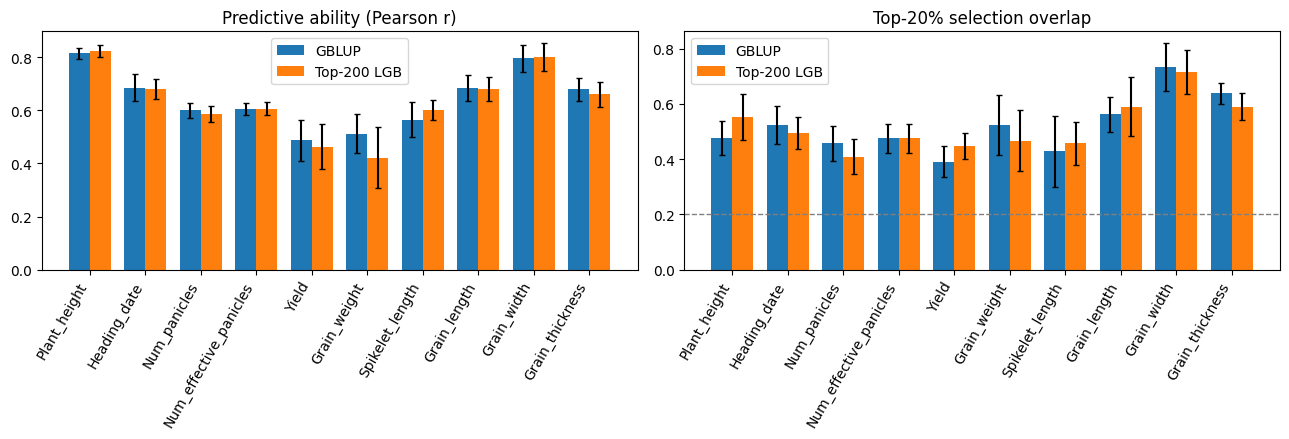

In [15]:
# predictive ability (Pearson) and top-20% overlap across traits, top-200 LightGBM vs GBLUP
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(traits)); w = 0.38
for a, k, ttl in [(ax[0], 'Pearson', 'Predictive ability (Pearson r)'),
                  (ax[1], 'TopOverlap', 'Top-20% selection overlap')]:
    a.bar(x - w/2, [cv_results[t]['metrics']['gblup'][k][0] for t in traits], w,
          yerr=[cv_results[t]['metrics']['gblup'][k][1] for t in traits], label='GBLUP', capsize=2)
    a.bar(x + w/2, [cv_results[t]['metrics']['top200'][k][0] for t in traits], w,
          yerr=[cv_results[t]['metrics']['top200'][k][1] for t in traits], label='Top-200 LGB', capsize=2)
    a.set_xticks(x); a.set_xticklabels(traits, rotation=60, ha='right'); a.set_title(ttl)
    a.legend()
ax[1].axhline(TOP_FRAC, color='grey', ls='--', lw=1)
plt.tight_layout()
plt.savefig(f"{OUT}/metrics_pearson_topoverlap.png", dpi=150)
plt.show()